In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('custdata.tsv', sep='\t', keep_default_na=False)
df.shape

(1000, 11)

In [2]:
df['housing.type'].value_counts()

housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
NA                               56
Occupied with no rent            11
Name: count, dtype: int64

In [3]:
col = df['housing.type'].str.strip()
n_before = len(col)

keep = (col != '') & (col.str.upper() != 'NA')
clean = col[keep]
n_dropped = n_before - len(clean)

print(f'Excluded {n_dropped} of {n_before} rows ({n_dropped/n_before:.1%}) because housing.type was NA/missing; {len(clean)} rows remain.')

Excluded 56 of 1000 rows (5.6%) because housing.type was NA/missing; 944 rows remain.


In [4]:
counts = clean.value_counts()
counts

housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
Occupied with no rent            11
Name: count, dtype: int64

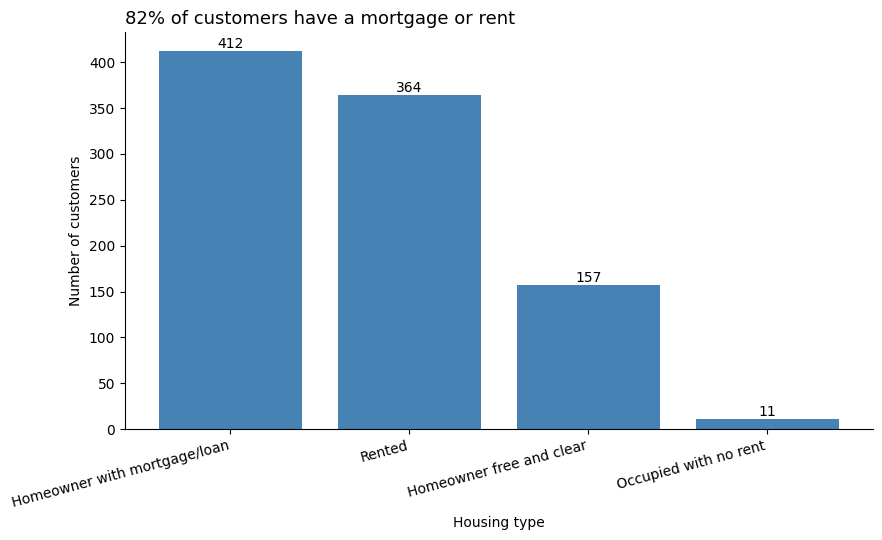

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(counts.index, counts.values, color='steelblue')
ax.bar_label(ax.containers[0])
ax.set_title('82% of customers have a mortgage or rent', fontsize=13, loc='left')
ax.set_xlabel('Housing type')
ax.set_ylabel('Number of customers')
plt.xticks(rotation=15, ha='right')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Rows excluded:** 56 of the 1,000 rows(5.6%) were excluded because their housing.type was NA.